# Projet ML : Classification binaire : **Spambase**


On applique le workflow de `ml_workflow.py` au jeu Spambase (UCI) : prédire si un e-mail est un spam (`1`) ou non (`0`) à partir de 57 fréquences de mots et de caractères.

Étapes : import, pré-traitement (valeurs manquantes, centrage-réduction, ACP), split train/test, entraînement avec sélection de variables, validation. Toutes les décisions (modèle, nombre de variables, hyperparamètres, seuil) sont prises par validation croisée sur le train. Le test ne sert qu'à l'évaluation finale.

In [22]:
import pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import ml_workflow as ml

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100
SEED = ml.RANDOM_STATE

## 1. Import et description des données  


In [23]:
# Loading data
df_spam = ml.load_spambase()

# what it looks like
display(df_spam.head())

# Dimension
print("Dimensions :", df_spam.shape)

# General description
display(ml.describe_dataset(df_spam, "is_spam"))

# Target distribution
display(df_spam["is_spam"].value_counts())

# percentage distribution
display(
    df_spam["is_spam"]
    .value_counts(normalize=True)
    .mul(100)
)


X_spam, y_spam = ml.split_features_target(
    df_spam,
    "is_spam"
)

print("X :", X_spam.shape)
print("y :", y_spam.shape)

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,is_spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


Dimensions : (4601, 58)


n_rows                                                          4601
n_columns                                                         58
n_features                                                        57
n_missing_values                                                   0
n_duplicated_rows                                                391
target                                                       is_spam
class_counts                                      {0: 2788, 1: 1813}
class_proportions    {0: 0.6059552271245382, 1: 0.39404477287546186}
dtype: object

is_spam
0    2788
1    1813
Name: count, dtype: int64

is_spam
0    60.595523
1    39.404477
Name: proportion, dtype: float64

X : (4601, 57)
y : (4601,)


## 2. Valeurs manquantes simulées et split train/test

Comme il n'y a pas de valeur manquante, on en injecte 5 % au hasard (MCAR) pour pouvoir tester l'imputation. Le split est stratifié (80/20) pour garder la même proportion de spams dans les deux parties.

In [24]:
# Missing values simulation
X_spam_missing = ml.inject_missing_values(
    X_spam,
    frac=0.05,
    seed=SEED
)

# Stratified train/test split
X_train_spam, X_test_spam, y_train_spam, y_test_spam = ml.split_data(
    X_spam_missing,
    y_spam,
    test_size=0.2,
    seed=SEED
)

print("Train :", X_train_spam.shape)
print("Test :", X_test_spam.shape)

print("\nDistribution du train :")
display(y_train_spam.value_counts(normalize=True))

print("\nDistribution du test :")
display(y_test_spam.value_counts(normalize=True))

print("\nValeurs manquantes dans le train :")
print(X_train_spam.isna().sum().sum())

print("\nValeurs manquantes dans le test :")
print(X_test_spam.isna().sum().sum())

Train : (3680, 57)
Test : (921, 57)

Distribution du train :


is_spam
0    0.605978
1    0.394022
Name: proportion, dtype: float64


Distribution du test :


is_spam
0    0.605863
1    0.394137
Name: proportion, dtype: float64


Valeurs manquantes dans le train :
10415

Valeurs manquantes dans le test :
2698


## 3. Pré-traitement  

In [25]:
# Pipeline showing
baseline_pipeline_spam = ml.build_pipeline(
    model=LogisticRegression(max_iter=1000),
    imputer_strategy="median",
    scale=True,
    selector=None,
    pca_components=None
)

# Structure
display(baseline_pipeline_spam)

print("\nÉtapes du pipeline :")
print(baseline_pipeline_spam.named_steps)

,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True



Étapes du pipeline :
{'imputer': SimpleImputer(strategy='median'), 'scaler': StandardScaler(), 'selector': 'passthrough', 'pca': 'passthrough', 'model': LogisticRegression(max_iter=1000)}


On compare d'abord l'imputation par la moyenne et par la médiane, avec une régression logistique (rapide) en validation croisée sur le train.

In [26]:
imputation_table = pd.concat({
    strategy: ml.cross_validate_models(
        {"lr": LogisticRegression(max_iter=1000, random_state=SEED)},
        X_train_spam, y_train_spam, cv=5, imputer_strategy=strategy,
    )
    for strategy in ("mean", "median")
}).droplevel(1)
imputation_table.round(3)

,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,fit_time_s
mean,0.897,0.014,0.968,0.006,0.945,0.012,0.039
median,0.896,0.012,0.970,0.006,0.947,0.012,0.049


Les deux stratégies donnent le même résultat : PR-AUC de 0,945 ± 0,012 (moyenne) et 0,947 ± 0,012 (médiane). L'écart est bien plus petit que l'écart-type, on ne peut pas départager. On garde la médiane, moins sensible aux valeurs extrêmes, nombreuses sur ces fréquences très asymétriques.

## 4. Comparaison de plusieurs méthodes de classification  

In [27]:
models = ml.get_models(
    class_weight="balanced",
    include_svm=True,
    random_state=SEED,
)

model_comparison = ml.cross_validate_models(
    models,
    X_train_spam,
    y_train_spam,
    cv=5,
    scoring=("f1", "roc_auc", "average_precision"),
)

display(
    model_comparison
    .round(3)
    .sort_values("average_precision_mean", ascending=False)
)


,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,fit_time_s
rf,0.934,0.006,0.984,0.004,0.979,0.005,0.593
hgb,0.939,0.011,0.986,0.003,0.978,0.005,0.803
SVM-RBF,0.907,0.012,0.971,0.004,0.957,0.007,0.177
lr,0.901,0.012,0.970,0.006,0.948,0.012,0.048


Le Random Forest (PR-AUC 0,979 ± 0,005) et HGB (0,978 ± 0,005) sont devant le SVM (0,957) et la régression logistique (0,948). L'écart entre RF et HGB est inférieur à l'écart-type : on ne sait pas lequel est vraiment meilleur. On retient le RF sur la meilleure moyenne. Il est aussi plus rapide à entraîner (colonne `fit_time_s`, qui dépend de la machine).

## 5. Sélection de variables

On compare quatre sélecteurs (ANOVA, information mutuelle, L1, importances d'un Random Forest) pour k = 5, 10, 15 et 20, avec une régression logistique pondérée. Le sélecteur est dans le pipeline, donc refait à chaque pli.

In [28]:
selector_model = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=SEED
)

selector_table = ml.compare_feature_selectors(
    selector_model,
    X_train_spam,
    y_train_spam,
    methods=("anova", "mutual_info", "l1", "rf"),
    k_values=(5, 10, 15, 20),
    cv=5,
    scoring="average_precision",
)

display(
    selector_table
    .round(3)
    .sort_values("average_precision_mean", ascending=False)
)


,,average_precision_mean,average_precision_std,fit_time_s
method,k,,,
l1,20,0.943,0.011,0.123
rf,20,0.937,0.009,0.460
mutual_info,20,0.934,0.009,0.497
rf,15,0.933,0.009,0.496
l1,15,0.933,0.023,0.159
mutual_info,15,0.931,0.009,0.623
anova,20,0.920,0.012,0.045
l1,10,0.920,0.020,0.117
anova,15,0.912,0.007,0.045


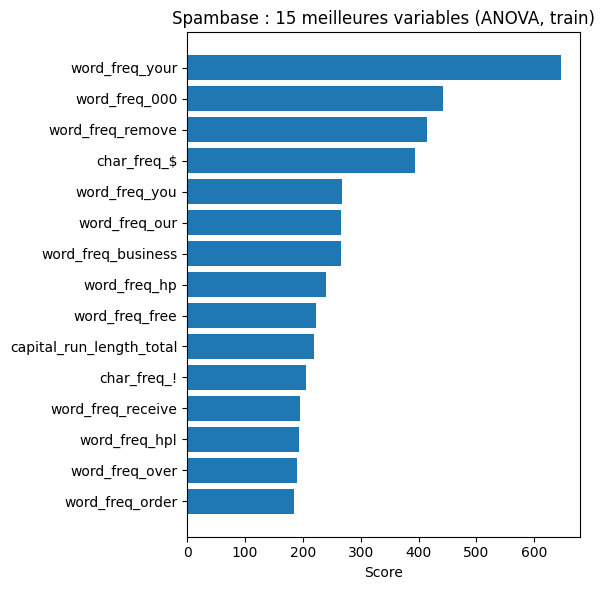

In [29]:
# Scores ANOVA calculés sur le train uniquement
ml.plot_feature_scores(ml.feature_scores(X_train_spam, y_train_spam, "anova"), top=15,
                       title="Spambase : 15 meilleures variables (ANOVA, train)");

Les variables les plus liées à la cible sont des mots typiques des spams commerciaux (`your`, `000`, `remove`, `$`, `business`). `hp` (nom de l'entreprise des donneurs) apparaît aussi : elle signale plutôt un e-mail légitime, ce qui rappelle que ce jeu est propre à un contexte.

## 6. Réglage des hyperparamètres du Random Forest

Le Random Forest est réglé par `GridSearchCV` sur le train (5 plis, critère PR-AUC). On mesure aussi l'effet de l'ACP à 95 % de variance sur la régression logistique.

In [30]:
# Réglage des hyperparamètres du Random Forest sur le train uniquement
# Paramètres choisis pour contrôler la capacité et le compromis biais/variance :
# nombre d'arbres, profondeur maximale, nombre minimal d'échantillons par feuille
# et fraction de variables testées à chaque séparation.
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)
rf_pipe = ml.build_pipeline(rf)
rf_grid = ml.tune_model(
    rf_pipe,
    {
        "model__max_depth": [None, 12],
        "model__min_samples_leaf": [1, 3],
        "model__max_features": ["sqrt", 0.5],
    },
    X_train_spam,
    y_train_spam,
    scoring="average_precision",
    cv=5,
)
print("Meilleurs hyperparamètres RF :", rf_grid.best_params_)
print("Meilleure PR-AUC moyenne en CV :", round(rf_grid.best_score_, 3))

# L'ACP reste évaluée séparément pour documenter son effet sur ce jeu de données.
pca_table = ml.compare_pca(
    selector_model,
    X_train_spam,
    y_train_spam,
    pca_components=(None, 0.95),
    cv=5,
    scoring="average_precision",
)
display(pca_table.round(3).sort_values("average_precision_mean", ascending=False))

Meilleurs hyperparamètres RF : {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}
Meilleure PR-AUC moyenne en CV : 0.979


,average_precision_mean,average_precision_std,fit_time_s
none,0.948,0.012,0.037
0.95,0.945,0.013,0.046


## 7. Configuration finale et évaluation sur le test

On vérifie d'abord, toujours en validation croisée sur le train, si le modèle retenu gagne à utiliser la sélection de variables ou l'ACP. Ensuite seulement on évalue sur le test, au seuil 0,5 et au seuil qui maximise le F1 sur des scores hors-échantillon du train.

In [31]:
# Modèle retenu = meilleure PR-AUC moyenne en validation croisée (section 4)
best_name = model_comparison["average_precision_mean"].idxmax()
best_model = models[best_name]

# Si RF est retenu, utiliser les hyperparamètres validés en section 6.
if best_name == "rf":
    best_model = clone(rf_grid.best_estimator_.named_steps["model"])

# Le modèle retenu profite-t-il de la sélection de variables ou de l'ACP ?
# Toutes les configurations sont comparées uniquement sur le train.
best_sel = selector_table["average_precision_mean"].idxmax()  # (méthode, k)
candidates = {
    "sans sélection ni ACP": {},
    f"sélection {best_sel[0]} (k={best_sel[1]})": dict(selector=best_sel[0], k=best_sel[1]),
    "ACP (95 % de variance)": dict(pca_components=0.95),
}
rows = {
    label: ml.cross_validate_models(
        {best_name: best_model},
        X_train_spam,
        y_train_spam,
        cv=5,
        **kw,
    ).loc[best_name]
    for label, kw in candidates.items()
}
config_table = pd.DataFrame(rows).T
display(config_table.round(3).sort_values("average_precision_mean", ascending=False))

best_label = config_table["average_precision_mean"].idxmax()
best_params = candidates[best_label]
print(f"Modèle retenu : {best_name} | hyperparamètres RF : {rf_grid.best_params_}")
print(f"Configuration retenue : {best_label}")

,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,fit_time_s
sans sélection ni ACP,0.931,0.005,0.984,0.003,0.979,0.005,0.490
sélection l1 (k=20),0.915,0.010,0.977,0.005,0.965,0.011,0.442
ACP (95 % de variance),0.908,0.015,0.972,0.007,0.961,0.009,1.210


Modèle retenu : rf | hyperparamètres RF : {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}
Configuration retenue : sans sélection ni ACP


In [32]:
final = ml.build_pipeline(clone(best_model), **best_params)

# Seuil de décision appris sur le train uniquement (scores hors-échantillon)
oof = ml.oof_scores(final, X_train_spam, y_train_spam, cv=3)
thr = ml.find_best_threshold(y_train_spam, oof, metric="f1")
final.fit(X_train_spam, y_train_spam)

res = pd.DataFrame({
    "seuil par défaut": ml.evaluate_model(final, X_test_spam, y_test_spam),
    f"seuil optimisé ({thr:.2f})": ml.evaluate_model(final, X_test_spam, y_test_spam, threshold=thr),
}).round(3)
res

,seuil par défaut,seuil optimisé (0.48)
accuracy,0.939,0.939
balanced_accuracy,0.933,0.934
precision,0.940,0.932
recall,0.904,0.912
f1,0.921,0.922
mcc,0.872,0.872
roc_auc,0.982,0.982
pr_auc,0.974,0.974


,accuracy,balanced_accuracy,precision,recall,f1,mcc,roc_auc,pr_auc
lr,0.919,0.917,0.885,0.912,0.898,0.831,0.969,0.945
rf,0.945,0.942,0.931,0.928,0.930,0.884,0.983,0.977
hgb,0.947,0.945,0.931,0.934,0.933,0.889,0.988,0.981
SVM-RBF,0.919,0.913,0.904,0.887,0.896,0.829,0.967,0.946


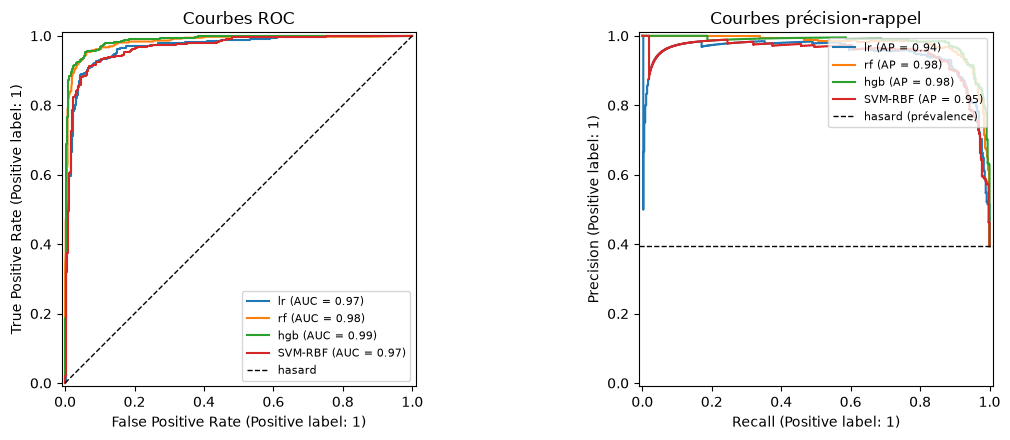

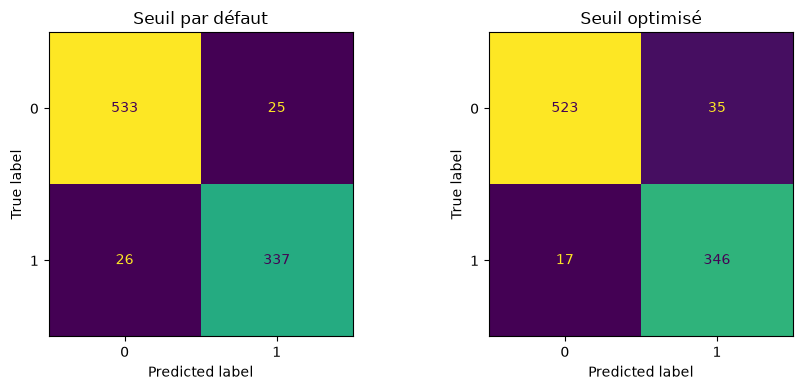

In [24]:
# Tous les modèles sur le test : le RF de la comparaison est le RF réglé (section 6), comme le modèle final
models_final = {**models, "rf": clone(rf_grid.best_estimator_.named_steps["model"])}
table, fitted = ml.compare_models(models_final, X_train_spam, y_train_spam, X_test_spam, y_test_spam, **best_params)
display(table.round(3))
ml.plot_roc_pr(fitted, X_test_spam, y_test_spam)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ml.plot_confusion(final, X_test_spam, y_test_spam, title="Seuil par défaut", ax=axes[0])
ml.plot_confusion(final, X_test_spam, y_test_spam, threshold=thr, title="Seuil optimisé", ax=axes[1])
plt.tight_layout()

## 8. Conclusions pour Spambase  

On cherche à séparer les spams des e-mails légitimes à partir de 57 variables. Toutes les décisions ont été prises par validation croisée sur le train ; le test (921 e-mails) n'a servi qu'à la fin.

**Méthode retenue : Random Forest pondéré** (`n_estimators=200`, `max_features="sqrt"`, `class_weight="balanced"`), sur les 57 variables, sans sélection ni ACP, avec imputation par la médiane.

Pourquoi ce choix. En CV, le RF a la meilleure PR-AUC (0,979 ± 0,005), au coude à coude avec HGB (0,978 ± 0,005) et nettement devant le SVM (0,957) et la régression logistique (0,948). L'écart RF/HGB est dans le bruit ; le RF a l'avantage d'être plus rapide à entraîner et de n'avoir pas besoin de réglage (la grille confirme les valeurs par défaut). Ni la sélection de variables (L1, k = 20 : 0,972) ni l'ACP (0,963) n'améliorent le RF : l'ACP a besoin de 48 axes pour 95 % de la variance, les variables apportent donc des informations assez indépendantes.

Résultats sur le test. Au seuil 0,5 : accuracy 0,945, précision 0,931, rappel 0,928, F1 0,930, MCC 0,884, PR-AUC 0,977. Le jeu étant peu déséquilibré (39 % de spams), l'accuracy est ici un indicateur acceptable, mais on regarde surtout la précision : un e-mail légitime classé en spam coûte plus cher qu'un spam qui passe. C'est pourquoi on garde le seuil 0,5 plutôt que 0,43, qui augmente le rappel (0,953) mais baisse la précision à 0,908.

Limites. Un seul découpage train/test, et des écarts entre les meilleurs modèles plus petits que l'écart-type : une validation répétée serait nécessaire pour trancher entre RF et HGB. Les valeurs manquantes sont simulées (MCAR), ce qui est plus simple qu'un vrai mécanisme. Enfin, on n'a pas retiré les 391 lignes dupliquées : certaines peuvent se retrouver à la fois dans le train et dans le test et rendre le test un peu optimiste.